In [1]:
config_path = "config/params.yaml"
mode = "default"

In [2]:
# Parameters
config_path = "config/params.yaml"


# 10 — Model dan analisis terkontrol

**Tujuan:** tuning, tangga model, dan analisis di dalam sel aktivitas dan usia (RQ1), tahap pengembangan: train `w0–w1`, test `w2`.

In [3]:
import json
import os

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")  # mlruns/ tetap dipakai sebagai folder lokal

import mlflow
import numpy as np
import pandas as pd
import polars as pl

from ghremoval.analysis import bootstrap_gain, cells_of, du_name_baselines, hour_order, ladder, seeds
from ghremoval.config import load_context
from ghremoval.data import xy
from ghremoval.evaluate import within_cell_auc
from ghremoval.models.fit import arm_mask, fit_predict, load_stage, time_holdback
from ghremoval.models.tune import run_study
from ghremoval.quality import Checks
from ghremoval.report import save_table
from ghremoval.runlog import RunLog
from ghremoval.viz import new_figure, save_figure

ctx = load_context(config_path)
run = RunLog("10_models_and_controls", ctx.paths.run_log, ctx.paths.root)
checks = Checks()
models_cfg = ctx.p.locked["models"]
data = load_stage(ctx, "dev", 60)
assert set(data.train["week"].unique()) <= {"w0", "w1"} and set(data.test["week"].unique()) == {"w2"}
order = hour_order(ctx)
print("train:", data.train.height, "test:", data.test.height)

/home/s2_giga/mahathir/trial/dm-git/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train: 55439 test: 22095


## 1. Tuning

Objective: AP stratum 5–19 pada lengan F2. Early stopping memakai 20% jam terakhir train.

In [4]:
X, y = xy(data.train, "M_behav")
X_test, y_test = xy(data.test, "M_behav")
es = time_holdback(data.train, order)
tune_mask = arm_mask(data.train, data.test, "F2_forward_new_accounts", ctx) & (data.test["stratum"].to_numpy() == "5-19")
mlflow.set_tracking_uri(f"file:{ctx.paths.root}/mlruns")
mlflow.set_experiment("nb10_tuning")
storage = ctx.paths.results / "optuna"
studies = []
for family in ("xgb", "lr", "mlp"):
    for sampler_seed in models_cfg["optuna_sampler_seeds"]:
        result = run_study(family, sampler_seed, X, y, es, X_test, y_test, tune_mask, storage, models_cfg["optuna_trials"])
        studies.append(result)
        with mlflow.start_run(run_name=f"{family}_{sampler_seed}"):
            mlflow.log_params({"family": family, "sampler_seed": sampler_seed})
            mlflow.log_metrics({"best_ap_5_19": result["best_value"], "seconds": result["seconds"]})
        print(family, sampler_seed, round(result["best_value"], 4), round(result["seconds"]), "s", flush=True)
tuning = pd.DataFrame(studies)
save_table(tuning.drop(columns=["best_params"]).assign(best_params=tuning["best_params"].map(json.dumps)), "tab_tuning_trials", "Hyperparameter search: best value per family and sampler seed")
best = {family: tuning[tuning.family == family].sort_values("best_value", ascending=False).iloc[0]["best_params"] for family in ("xgb", "lr", "mlp")}
(ctx.paths.results / "best_params.json").write_text(json.dumps(best, indent=2) + "\n")
tuning[["family", "sampler_seed", "best_value", "n_trials", "seconds"]]

2026/11/10 18:43:35 INFO mlflow.tracking.fluent: Experiment with name 'nb10_tuning' does not exist. Creating a new experiment.


xgb 42 0.1765 14 s


xgb 123 0.1849 31 s


xgb 2026 0.181 18 s


lr 42 0.1396 28 s


lr 123 0.1396 28 s


lr 2026 0.1396 29 s


mlp 42 0.1922 132 s


mlp 123 0.1914 159 s


mlp 2026 0.1948 154 s


,family,sampler_seed,best_value,n_trials,seconds
0,xgb,42,0.176463,24,13.746322
1,xgb,123,0.184877,24,30.644345
2,xgb,2026,0.181013,24,18.492277
3,lr,42,0.139575,24,27.765815
4,lr,123,0.139565,24,27.529354
5,lr,2026,0.139555,24,29.291144
6,mlp,42,0.192212,24,131.949139
7,mlp,123,0.191380,24,158.924104
8,mlp,2026,0.194782,24,154.084787


## 2. Tangga model

In [5]:
result = ladder(ctx, "dev", data, best)
table = pd.DataFrame(result["rows"])
table = pd.concat([table, pd.DataFrame(du_name_baselines(ctx, data))], ignore_index=True)
save_table(table, "tab_models_by_stratum", "Model ladder per stratum, development stage (observed label)")
view = table[table.arm == "F2_forward_new_accounts"][["model", "n", "n_pos", "base_5-19", "ap_all", "ap_5-19", "ap_20+", "within_cell_auc", "p_at_100"]]
view

,model,n,n_pos,base_5-19,ap_all,ap_5-19,ap_20+,within_cell_auc,p_at_100
1,B0_rank_events,22095,560,0.02423,0.031506,0.023988,0.078396,0.508363,0.13
4,B1_age,22095,560,0.02423,0.076213,0.073642,0.126798,0.500000,0.09
7,B2_xgb,22095,560,0.02423,0.076360,0.071042,0.128530,0.500000,0.11
10,B2_lr,22095,560,0.02423,0.079065,0.071587,0.150722,0.500000,0.14
13,M_behav_xgb,22095,560,0.02423,0.202880,0.183842,0.425488,0.658849,0.54
16,M_behav_lr,22095,560,0.02423,0.155927,0.139491,0.336395,0.639245,0.46
19,M_behav_mlp,22095,560,0.02423,0.201507,0.183257,0.438791,0.661235,0.52
22,M_robust_xgb,22095,560,0.02423,0.150839,0.133783,0.350362,0.644821,0.44
24,B3_du_intervals,22095,560,0.02423,0.070433,0.057721,0.217115,NaN,0.20
26,B3_name_heuristic,22095,560,0.02423,0.036816,0.034516,0.111329,NaN,0.06


## 3. Keputusan keluarga model

Model yang lebih mahal dari XGBoost dipertahankan hanya jika CI paired-nya positif dan selisih AP melewati ambang.

In [6]:
scores = {name: value[0] for name, value in result["models"].items()}
per_seed = [fit_predict("xgb", best["xgb"], "M_behav", data.train, [data.test], order, [seed])[0] for seed in seeds(ctx)]
mask = arm_mask(data.train, data.test, "F2_forward_new_accounts", ctx) & (data.test["stratum"].to_numpy() == "5-19")
from sklearn.metrics import average_precision_score  # noqa: E402

seed_ap = [average_precision_score(y_test[mask], s[mask]) for s in per_seed]
effective_delta = max(ctx.p.locked["decision"]["min_delta_ap"], 2 * float(np.std(seed_ap)))
print("AP per seed:", np.round(seed_ap, 4), "ambang efektif:", round(effective_delta, 4))
comparisons = {"M_behav_xgb - B2_xgb": ("M_behav_xgb", "B2_xgb"), "M_behav_mlp - M_behav_xgb": ("M_behav_mlp", "M_behav_xgb"), "M_behav_lr - M_behav_xgb": ("M_behav_lr", "M_behav_xgb")}
decisions = {}
for name, (a, b) in comparisons.items():
    for arm in ("F2_forward_new_accounts", "F3_forward_batch_excluded"):
        decisions[f"{name} | {arm}"] = bootstrap_gain(ctx, data, scores[a], scores[b], arm, "5-19")
decision_table = pd.DataFrame(decisions).T
save_table(decision_table.reset_index(names="comparison"), "tab_model_decisions_dev", "Paired AP differences, 5-19 events, development stage")
(ctx.paths.results / "model_decisions_dev.json").write_text(json.dumps({"effective_delta": effective_delta, "seed_ap": seed_ap, "decisions": decisions}, indent=2, default=float) + "\n")
decision_table[["delta", "low", "high", "p_one_sided", "n_clusters_with_pos", "delta_without_largest_cluster"]]

AP per seed: [0.1849 0.1833 0.1815] ambang efektif: 0.01


,delta,low,high,p_one_sided,n_clusters_with_pos,delta_without_largest_cluster
M_behav_xgb - B2_xgb | F2_forward_new_accounts,0.112800,0.070370,0.155436,0.0000,364.0,0.106312
M_behav_xgb - B2_xgb | F3_forward_batch_excluded,0.087025,0.040245,0.136155,0.0000,276.0,0.077575
M_behav_mlp - M_behav_xgb | F2_forward_new_accounts,-0.000585,-0.017478,0.018423,0.4915,364.0,-0.001376
M_behav_mlp - M_behav_xgb | F3_forward_batch_excluded,0.014392,-0.000801,0.029771,0.0305,276.0,0.013634
M_behav_lr - M_behav_xgb | F2_forward_new_accounts,-0.044351,-0.084765,-0.001829,0.9775,364.0,-0.040267
M_behav_lr - M_behav_xgb | F3_forward_batch_excluded,-0.061325,-0.104112,-0.019667,1.0000,276.0,-0.055376


## 4. Peringkat di dalam sel aktivitas dan usia

{'B2_xgb': 0.5, 'M_behav_xgb': 0.6588491870574721, 'M_robust_xgb': 0.6448213781889655}


[PosixPath('/home/s2_giga/mahathir/trial/dm-git/results/figures/fig_within_cell.pdf'),
 PosixPath('/home/s2_giga/mahathir/trial/dm-git/results/figures/fig_within_cell.png')]

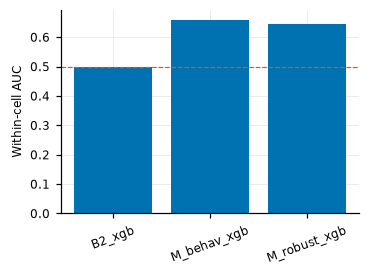

In [7]:
cells = cells_of(data.test)
f2 = arm_mask(data.train, data.test, "F2_forward_new_accounts", ctx)
inside = {name: within_cell_auc(y_test[f2], scores[name][f2], cells[f2]) for name in ("B2_xgb", "M_behav_xgb", "M_robust_xgb")}
print(inside)
fig, ax = new_figure()
ax.bar(list(inside), list(inside.values()), color="#0072B2")
ax.axhline(0.5, color="#D55E00", lw=0.8, ls="--")
ax.set_ylabel("Within-cell AUC")
ax.tick_params(axis="x", labelrotation=20)
save_figure(fig, "fig_within_cell")

## Ringkasan & cek

In [8]:
checks.add("Q17", "w3" not in set(data.train["week"].unique()) | set(data.test["week"].unique()), "tanpa w3")
checks.add("kelengkapan", len(studies) == 9, f"{len(studies)} studi")
checks.raise_if_failed()
print(run.finish(n_train=data.train.height, n_test=data.test.height))

[LULUS] Q17: tanpa w3
[LULUS] kelengkapan: 9 studi
{'notebook': '10_models_and_controls', 'finished_at_utc': '2026-11-10T11:55:53+00:00', 'git_commit': 'f04dbd3', 'duration_seconds': 739.4, 'counts': {'n_train': 55439, 'n_test': 22095}}
